<a href="https://colab.research.google.com/github/bvsvntv/ai-ml-learning/blob/main/notebooks/lang-graph/chatbot_with_hitl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U langchain-openai

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.messages import AnyMessage, AIMessage, BaseMessage, HumanMessage
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command
from typing import TypedDict, Annotated
from google.colab import userdata
import requests

from IPython.display import Image

In [49]:
api_key = userdata.get("OPENAI_API_KEY")
alphavantage_api_key = userdata.get("ALPHAVANTAGE_API_KEY")
llm = ChatOpenAI(api_key=api_key, model="gpt-6-luna")

In [50]:
def get_stock_price(symbol: str) -> str:
  """
  Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA')
  using Alpha Vantage with API key in the URL.
  """

  params = {
      "function": "GLOBAL_QUOTE",
      "symbol": symbol,
      "apikey": alphavantage_api_key
  }

  url="https://www.alphavantage.co/query"

  response = requests.get(url, params=params)
  return response.json()

def purchase_stock(symbol: str, quantity: int) -> dict:
  """
  Simulate purchasing a given quantity of a stock symbol.

  HUMAN-IN-THE-LOOP:
  Before confirming the purchase, this tool will interrupt
  and wait for a human decision ("yes" / anything else).
  """

  # this pauses the graph and returns control to the caller
  decision = interrupt(f"Approve buying {quantity} shares of {symbol}? (yes/no)")

  if isinstance(decision, str) and decision.lower() == "yes":
    return {
      "status": "success",
      "message": f"Purchase order placed for {quantity} shares of {symbol}.",
      "symbol": symbol,
      "quantity": quantity,
    }
  else:
    return {
      "status": "cancelled",
      "message": f"Purchase of {quantity} shares of {symbol} was declined by human.",
      "symbol": symbol,
      "quantity": quantity,
    }

In [51]:
tools = [get_stock_price, purchase_stock]
llm_with_tools = llm.bind_tools(tools)

In [52]:
# state
class ChatState(TypedDict):
  messages: Annotated[list[BaseMessage], add_messages]

In [53]:
def chat_node(state: ChatState):
  """LLM node that may answer or request a tool call."""
  messages = state["messages"]
  response = llm_with_tools.invoke(messages)
  return {"messages": [response]}

tool_node = ToolNode(tools)

In [54]:
# checkpointer
checkpointer = MemorySaver()

In [55]:
# graph
graph = StateGraph(ChatState)
graph.add_node("chat", chat_node)
graph.add_node("tools", tool_node)

graph.add_edge(START, "chat")
graph.add_conditional_edges("chat", tools_condition)
graph.add_edge("tools", "chat")

chatbot = graph.compile(checkpointer=checkpointer)

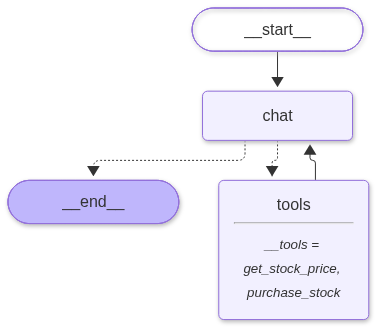

In [56]:
# view graph
Image(chatbot.get_graph().draw_mermaid_png())

In [60]:
thread_id = 1

while True:
  user_input = input("You: ")
  if user_input.strip().lower() in {"exit", "quit"}:
    print("Bot: bye!")
    break

  # initial state
  state = {"messages": [HumanMessage(content=user_input)]}

  # run the graph
  result = chatbot.invoke(
    state,
    config={"configurable": {"thread_id": thread_id}}
  )

  # check for HITL interrupts from purchase_stock
  interrupts = result.get("__interrupt__", [])

  if interrupts:
    prompt = interrupts[0].value
    print(f"HITL: {prompt}")

    decision = input("Your decision: ").strip().lower()

    # resume graph with human decision
    result = chatbot.invoke(
        Command(resume=decision),
        config={"configurable": {"thread_id": thread_id}}
    )
  print(f"Bot: {result["messages"][-1].content[0]["text"]}")

You: hi
Bot: Hi! What can I help you with?
You: What's the stock price of AAPL?
Bot: AAPL is **$355.63** per share, up **$7.12 (2.04%)** from the previous close. Latest trading data: **November 11, 2026**.
You: Buy me 100 stocks.
HITL: Approve buying 100 shares of AAPL? (yes/no)
Your decision: Yes
Bot: Purchase order placed for **100 shares of AAPL**.
You: quit
Bot: bye!
